# COS711 Assignment 2: Segmentation Results

This notebook presents **how well the final model segments solar filaments** (the "Segmentation Results"
section of the brief, 30 marks). It covers what the brief asks for:
1. Panoptic Quality calculated **locally** and on the **Kaggle leaderboard**;
2. **means and standard deviations** over multiple runs;
3. **comparisons between approaches**;
4. **the kinds of errors** the model makes;
5. **predicted masks on test images**, with discussion, showing **best and worst cases**.

Every code cell has a **What & why** note above it and an **Interpretation** note below it, written from the
real outputs.

**The model** (chosen in `experimental_setup.ipynb`): U-Net with an ImageNet-pretrained EfficientNet-B3
encoder, BCE+Dice loss, trained with early stopping. Post-processing: threshold 0.6, drop predicted blobs
under 500 pixels, average over 4 flips (test-time augmentation, TTA).

**Which images are used for what**
- **Report images** (99 validation images of fold 0) are never used to choose anything, so their PQ is an
  honest estimate. They have expert labels, so we can measure errors exactly.
- **Test images** (180) are Kaggle's. They have **no labels**, so their quality can only be judged by eye
  here and by the leaderboard.

## 0. Setup
**What & why.** Load the saved results and the final model with its exact post-processing settings, so
every number and picture below comes from the same model that produced `submission.csv`.

In [1]:
import json, time
from pathlib import Path
import numpy as np, pandas as pd, torch, cv2
import matplotlib.pyplot as plt
from scipy import ndimage
import filament_pipeline as fp

pd.set_option("display.width", 250)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PREPARED = "../data_prep/prepared"
SITES = {"B": "Big Bear", "C": "Cerro Tololo", "L": "Learmonth", "M": "Mauna Loa", "T": "El Teide", "U": "Udaipur"}
res = pd.read_csv("runs/results.csv")
pp = json.load(open("runs/postprocess.json"))
cv5 = json.load(open("runs/cv_5fold.json"))
ppr = pd.read_csv("runs/pp_report.csv")
W = res.set_index("name").loc[pp["model"]]
cfg = fp.Config(prepared_dir=PREPARED, name=pp["model"], arch=W.arch, encoder=W.encoder, threshold=pp["threshold"],
                min_area=int(pp["min_area"]), low_threshold=pp["low_threshold"], close_px=int(pp["close_px"]),
                tta=bool(pp["use_tta"]))
model = fp.load_model(cfg, f"runs/{pp['model']}/best.pt", DEVICE)
test = pd.read_csv(Path(PREPARED, "test_observations.csv"))
sub = pd.read_csv("submission.csv")
print(f"model {pp['model']}: {pp['params'] / 1e6:.1f}M parameters | threshold {cfg.threshold}, min_area {cfg.min_area}, TTA {cfg.tta}")
print(f"device {DEVICE} | {len(res)} sweep runs | {len(test)} test images | submission rows {len(sub)}")

model arch_smp_unet_efficientnet-b3: 13.2M parameters | threshold 0.6, min_area 500, TTA True
device cuda | 16 sweep runs | 180 test images | submission rows 1474


**Interpretation.** The final model and its settings are loaded. These are exactly the settings used to
write `submission.csv`.

## 1. Headline numbers: local PQ, variability, and the human ceiling
**What & why.** One table with every PQ that matters, each with what it measures. The brief asks for PQ
"calculated locally and on the Kaggle leaderboard (with means and standard deviations over multiple runs
where feasible)". PQ = SQ × RQ:
- **SQ** = how well our outlines overlap the expert's, for the filaments we found;
- **RQ** = how well we find each real filament as its own object without inventing extras.

The **human ceiling** is two annotators scored against each other on the same images (from data prep):
a model that agrees with the annotators as much as they agree with each other is doing as well as a
second expert.

In [2]:
final = ppr[(ppr.setting == "tuned") & (ppr.tta == True)].iloc[0]
default = ppr[(ppr.setting.str.startswith("default")) & (ppr.tta == False)].iloc[0]
tuned = ppr[(ppr.setting == "tuned") & (ppr.tta == False)].iloc[0]
cvp = pd.Series([f["report_pq"] for f in cv5["folds"]])
rows = [
    ("Final model: tuned post-processing + TTA", "99 report images", final.pq, final.sq, final.rq),
    ("Final model: tuned post-processing, no TTA", "99 report images", tuned.pq, tuned.sq, tuned.rq),
    ("Final model: default post-processing (0.5, 60 px)", "99 report images", default.pq, default.sq, default.rq),
    ("5-fold mean ± std (default post-processing)", "5 × held-out report images", cvp.mean(), np.nan, np.nan),
    ("Human ceiling: annotator vs annotator", "296 multi-annotated images", 0.340, 0.597, 0.538),
]
head = pd.DataFrame(rows, columns=["what", "images", "PQ", "SQ", "RQ"])
head.loc[3, "PQ"] = f"{cvp.mean():.3f} ± {cvp.std():.3f}"
head["PQ"] = head.PQ.map(lambda v: v if isinstance(v, str) else round(v, 3))
head.round(3)

,what,images,PQ,SQ,RQ
0,Final model: tuned post-processing + TTA,99 report images,0.396,0.673,0.588
1,"Final model: tuned post-processing, no TTA",99 report images,0.381,0.671,0.568
2,"Final model: default post-processing (0.5, 60 px)",99 report images,0.309,0.667,0.464
3,5-fold mean ± std (default post-processing),5 × held-out report images,0.298 ± 0.011,NaN,NaN
4,Human ceiling: annotator vs annotator,296 multi-annotated images,0.34,0.597,0.538


**Interpretation.**
- **Final local PQ: 0.396** (SQ 0.673 × RQ 0.588) on 99 held-out images that were never used for any choice.
- **That's above the human ceiling (0.340).** Two experts labelling the same image agree at 0.34; the model
  agrees with the annotators (pooled over all of them) better than they agree with each other. Both its outline
  quality (SQ 0.673 vs 0.597) and its recognition (RQ 0.588 vs 0.538) are higher.
- **5-fold mean ± std: 0.298 ± 0.011.** This is with default post-processing, so it's lower than 0.396; it
  answers a different question: how stable is the *model* across different solar rotations? The spread is small.
- Read as percentages: the model finds 64% of the real filaments, and 54% of what it predicts are real
  filaments (section 4). PQ is lower than both because it multiplies outline quality by recognition.

## 2. Comparison between approaches
**What & why.** The brief asks for "comparisons between approaches". Two views:
1. **Every trained approach** (16 runs: 4 losses, 9 architectures, second seeds, learning rates) on the same
   99 report images with the same default post-processing, so the only difference is the approach.
2. **What each step added for the final model**: default post-processing → tuned threshold and size filter
   → test-time augmentation.

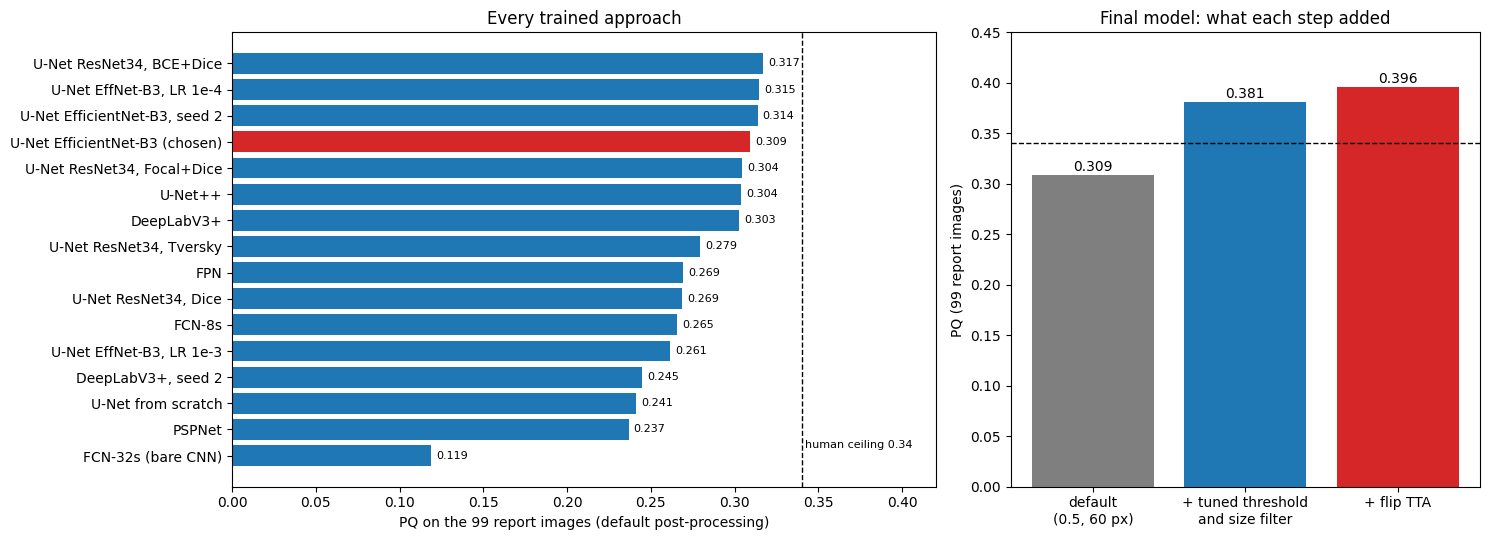

,approach,params_M,report_pq,report_sq,report_rq,report_tp,report_fp,report_fn
0,"U-Net ResNet34, BCE+Dice",24.4,0.317,0.669,0.474,726,1201,410
1,"U-Net EffNet-B3, LR 1e-4",13.2,0.315,0.669,0.470,806,1485,330
2,"U-Net EfficientNet-B3, seed 2",13.2,0.314,0.662,0.474,769,1342,367
3,U-Net EfficientNet-B3 (chosen),13.2,0.309,0.667,0.464,785,1466,351
4,"U-Net ResNet34, Focal+Dice",24.4,0.304,0.661,0.461,759,1400,377
5,U-Net++,26.1,0.304,0.658,0.462,722,1270,414
6,DeepLabV3+,22.4,0.303,0.659,0.459,692,1187,444
7,"U-Net ResNet34, Tversky",24.4,0.279,0.639,0.437,651,1191,485
8,FPN,23.1,0.269,0.649,0.415,696,1526,440
9,"U-Net ResNet34, Dice",24.4,0.269,0.660,0.407,683,1538,453


In [3]:
NAMES = {"arch_smp_unet_efficientnet-b3": "U-Net EfficientNet-B3 (chosen)", "seed2_smp_unet_efficientnet-b3": "U-Net EfficientNet-B3, seed 2",
         "loss_bce_dice": "U-Net ResNet34, BCE+Dice", "lr_0.0001_smp_unet_efficientnet-b3": "U-Net EffNet-B3, LR 1e-4",
         "arch_smp_deeplabv3p": "DeepLabV3+", "loss_focal_dice": "U-Net ResNet34, Focal+Dice", "arch_smp_unetpp": "U-Net++",
         "arch_fcn8": "FCN-8s", "loss_dice": "U-Net ResNet34, Dice", "arch_smp_fpn": "FPN", "loss_tversky": "U-Net ResNet34, Tversky",
         "lr_0.001_smp_unet_efficientnet-b3": "U-Net EffNet-B3, LR 1e-3", "arch_smp_pspnet": "PSPNet",
         "seed2_smp_deeplabv3p": "DeepLabV3+, seed 2", "arch_unet": "U-Net from scratch", "arch_fcn32": "FCN-32s (bare CNN)"}
t = res.assign(approach=res.name.map(NAMES), params_M=(res.params / 1e6).round(1)).sort_values("report_pq")
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
cols = ["tab:red" if "chosen" in a else "tab:blue" for a in t.approach]
ax[0].barh(t.approach, t.report_pq, color=cols)
ax[0].axvline(0.340, color="k", ls="--", lw=1); ax[0].text(0.342, 0.3, "human ceiling 0.34", fontsize=8)
ax[0].set(xlabel="PQ on the 99 report images (default post-processing)", title="Every trained approach", xlim=(0, 0.42))
for i, v in enumerate(t.report_pq): ax[0].text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8)
steps = [("default\n(0.5, 60 px)", default.pq), ("+ tuned threshold\nand size filter", tuned.pq), ("+ flip TTA", final.pq)]
ax[1].bar([s for s, _ in steps], [v for _, v in steps], color=["tab:gray", "tab:blue", "tab:red"])
for i, (_, v) in enumerate(steps): ax[1].text(i, v + 0.004, f"{v:.3f}", ha="center")
ax[1].axhline(0.340, color="k", ls="--", lw=1); ax[1].set(ylim=(0, 0.45), ylabel="PQ (99 report images)", title="Final model: what each step added")
plt.tight_layout(); plt.show()
t[["approach", "params_M", "report_pq", "report_sq", "report_rq", "report_tp", "report_fp", "report_fn"]].iloc[::-1].round(3).reset_index(drop=True)

**Interpretation.**
- **Left: every approach on the same images.** The leading group is tight: five U-Net runs between 0.309 and
  0.317, all within ~0.01 PQ, which is the noise level (section 3). Below them come U-Net++, DeepLabV3+ and
  Focal+Dice (~0.30), then overlap-only losses, FPN and FCN-8s (~0.27), and the weakest: U-Net trained from
  scratch (0.241), PSPNet (0.237) and the bare CNN (0.119).
- **No approach reaches the human ceiling with default post-processing.** The jump above it comes from
  post-processing, not from the architecture.
- **Note on the chosen model:** U-Net EfficientNet-B3 (red, 0.309) isn't the highest bar here. It was chosen on
  the 40 *monitor* images (where it was best), and on these 99 report images it sits within noise of the top.
  It wins the tie because it has 46% fewer parameters (13.2M vs 24.4M) and its second seed reproduced it
  (0.314). Picking the highest bar on this chart would mean choosing on the report images, which would make the
  reported score optimistic.
- **Right: what each step added for the final model.** Default 0.309 → tuned threshold and size filter
  **0.381 (+0.072)** → flip TTA **0.396 (+0.015)**. Post-processing is the biggest single gain: it roughly
  halves the false filaments (section 4).

## 3. Variability over multiple runs
**What & why.** One run on one validation fold can be lucky. Two kinds of repetition were done:
- **5-fold cross-validation:** the chosen configuration trained 5 times, each time on different solar
  rotations, scored on that fold's held-out report images;
- **a second random seed** for the two leading architectures (same data, different random initialisation
  and crop order).

All of these use default post-processing (threshold 0.5, 60 px), because the tuned settings were only
chosen on fold 0.

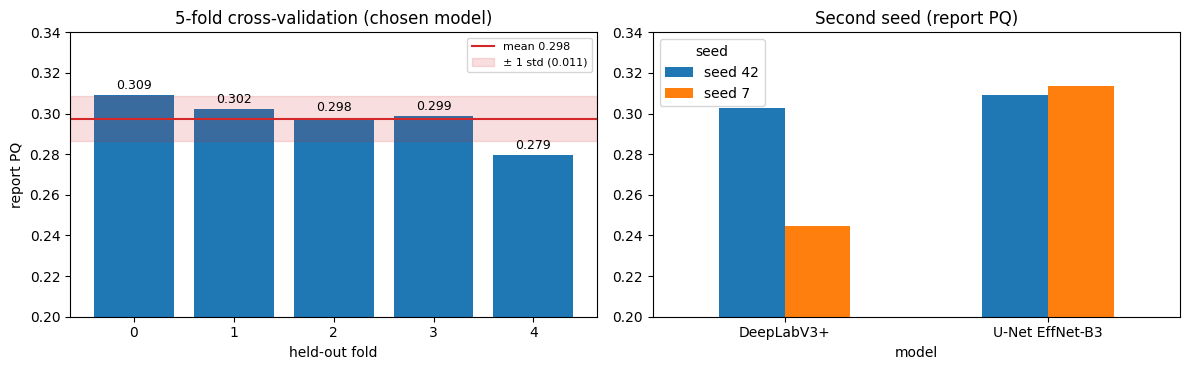

best epoch per fold: [12, 6, 15, 9, 13]


,model,seed,monitor_pq,report_pq,best_epoch
2,DeepLabV3+,seed 42,0.2944,0.3026,22
5,U-Net EffNet-B3,seed 42,0.3119,0.3092,12
14,DeepLabV3+,seed 7,0.2331,0.2447,6
15,U-Net EffNet-B3,seed 7,0.3100,0.3137,10


In [4]:
cvdf = pd.DataFrame(cv5["folds"])
seeds = res[res.name.isin(["arch_smp_unet_efficientnet-b3", "seed2_smp_unet_efficientnet-b3", "arch_smp_deeplabv3p", "seed2_smp_deeplabv3p"])]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(cvdf.fold.astype(str), cvdf.report_pq, color="tab:blue")
ax[0].axhline(cvdf.report_pq.mean(), color="tab:red", label=f"mean {cvdf.report_pq.mean():.3f}")
ax[0].axhspan(cvdf.report_pq.mean() - cvdf.report_pq.std(), cvdf.report_pq.mean() + cvdf.report_pq.std(), color="tab:red", alpha=.15, label=f"± 1 std ({cvdf.report_pq.std():.3f})")
for i, v in enumerate(cvdf.report_pq): ax[0].text(i, v + 0.003, f"{v:.3f}", ha="center", fontsize=9)
ax[0].set(ylim=(0.2, 0.34), xlabel="held-out fold", ylabel="report PQ", title="5-fold cross-validation (chosen model)"); ax[0].legend(fontsize=8)
lab = seeds.assign(model=seeds.name.str.replace("seed2_", "").map({"arch_smp_unet_efficientnet-b3": "U-Net EffNet-B3", "smp_unet_efficientnet-b3": "U-Net EffNet-B3",
                                                                 "arch_smp_deeplabv3p": "DeepLabV3+", "smp_deeplabv3p": "DeepLabV3+"}),
                   seed=np.where(seeds.name.str.startswith("seed2"), "seed 7", "seed 42"))
lab.pivot(index="model", columns="seed", values="report_pq").plot.bar(ax=ax[1], rot=0, title="Second seed (report PQ)")
ax[1].set_ylim(0.2, 0.34); plt.tight_layout(); plt.show()
print("best epoch per fold:", cvdf.best_epoch.tolist())
lab[["model", "seed", "monitor_pq", "report_pq", "best_epoch"]].round(4)

**Interpretation.**
- **5-fold: 0.298 ± 0.011** (range 0.279–0.309). Four folds lie within 0.298–0.309; fold 4 is lowest but within
  two standard deviations. So the model behaves consistently on different solar rotations, and differences
  smaller than ~0.01 between approaches should be treated as noise.
- **Fold 0, where all the choices were made, is the best fold (0.309).** That's the expected small optimism of
  choosing on one fold, and it's why the 5-fold mean is the fairer "how good is the model" number.
- **Second seed:** U-Net EfficientNet-B3 reproduces (0.309 vs 0.314); DeepLabV3+ doesn't (0.303 vs 0.245).
  One good run of DeepLabV3+ was partly luck; the chosen model isn't.
- Early stopping chose different epochs per fold (6 to 15), so no single fixed epoch count would suit all folds.

## 4. What kinds of errors does the model make?
**What & why.** PQ only says *how much* is wrong. To explain the results (and guide the Enhancement work)
we need to know *what* goes wrong. We run the final model on the 99 report images and compare every
prediction with every annotator's filaments:
- **missed filaments (FN)** by **size** and by **position** (near the edge of the disk, or the centre);
- **false filaments (FP)** by size;
- **fragmentation** (one real filament covered by several predictions) and **merging** (one prediction
  covering several real filaments);
- **annotator disagreement:** on images labelled by 2–3 people, is a "missed" filament one the other
  annotators also drew (a real miss), or one only this annotator drew? Is a "false" filament one that
  another annotator did draw?

A real filament counts as found when one prediction overlaps it with IoU > 0.5, the same rule as Kaggle.
This cell takes a few minutes (it re-predicts the 99 images with TTA).

419s | 1136 (image, annotator, filament) cases, 1351 (image, annotator, prediction) cases
found 64% of real filaments | 54% of predictions are real | fragmented 6.2%


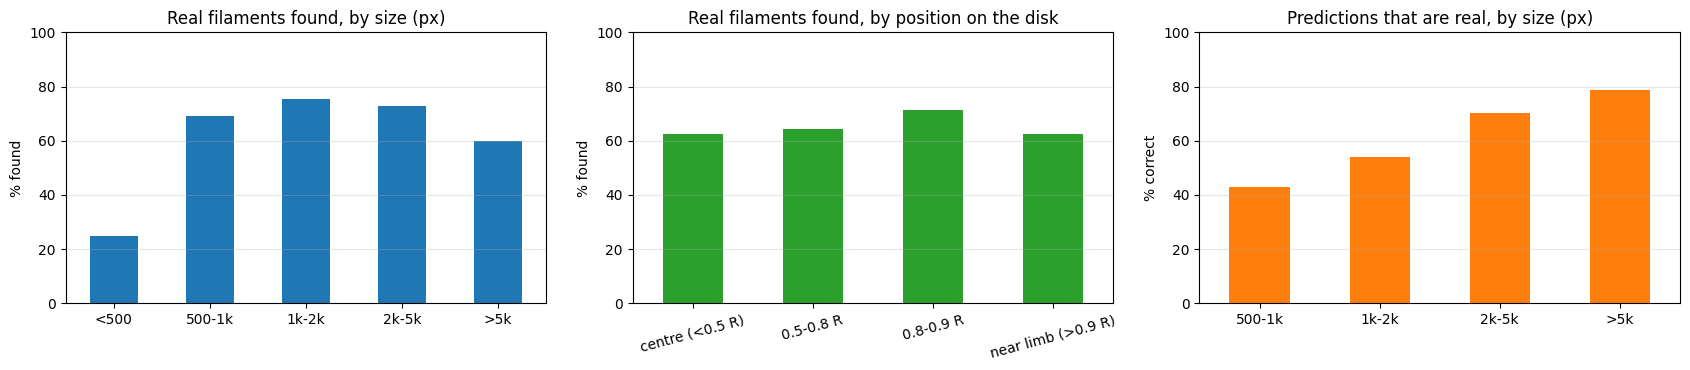

by size:
         filaments  found  fragmented
size                                
<500          169  0.249       0.000
500-1k        280  0.693       0.000
1k-2k         316  0.753       0.019
2k-5k         271  0.727       0.111
>5k           100  0.600       0.350

by position:
                     filaments  found
position                            
centre (<0.5 R)           420  0.624
0.5-0.8 R                 576  0.642
0.8-0.9 R                 132  0.712
near limb (>0.9 R)          8  0.625

predictions by size:
         predictions  correct
size                        
500-1k          571    0.429
1k-2k           415    0.540
2k-5k           295    0.702
>5k              70    0.786

images with 2-3 annotators - real filaments:
                                  filaments  found
consensus                                        
drawn by this annotator only           219  0.342
also drawn by another annotator        429  0.828

images with 2-3 annotators - 'false' predictions 

In [5]:
gts = fp._gt_table(cfg)
rep = fp.val_observations(cfg, "report")
c0, R, _ = fp._canon_geometry(cfg)

def iou_pairs(a, b):
    # IoU of every overlapping (instance in a, instance in b) pair -> dict
    both = (a > 0) & (b > 0)
    if not both.any(): return {}
    base = int(b.max()) + 1
    pairs, inter = np.unique(a[both].astype(np.int64) * base + b[both], return_counts=True)
    aa = np.bincount(a.ravel()); bb = np.bincount(b.ravel())
    return {(int(p // base), int(p % base)): it / (aa[p // base] + bb[p % base] - it) for p, it in zip(pairs, inter)}

t0 = time.time(); G, P = [], []
for o in rep.itertuples():
    M = np.array([getattr(o, c) for c in fp.MCOLS], np.float32).reshape(2, 3)
    pred = fp.to_original(fp.prob_to_instances(fp.predict_prob(model, fp.load_image(cfg, o.obs), cfg, DEVICE), cfg), M)
    sids = o.set_ids.split("|"); gt = {s: fp.ann_to_instmap_from_rle(gts[s]) for s in sids}
    pids = np.unique(pred[pred > 0]); pareas = np.bincount(pred.ravel())
    for s in sids:
        g = gt[s]; gids = np.unique(g[g > 0])
        ip = iou_pairs(g, pred)
        g_hit = {gi for (gi, pj), v in ip.items() if v > 0.5}; p_hit = {pj for (gi, pj), v in ip.items() if v > 0.5}
        n_cover = pd.Series([gi for (gi, pj) in ip]).value_counts() if ip else pd.Series(dtype=int)
        others = [gt[x] for x in sids if x != s]
        cons = {}
        for other in others:                                   # filaments another annotator also drew
            for (gi, oj), v in iou_pairs(g, other).items():
                if v > 0.5: cons[gi] = True
        cms = ndimage.center_of_mass(np.ones_like(g), g, gids) if len(gids) else []
        gareas = np.bincount(g.ravel())
        for gi, (cy, cx) in zip(gids, cms):
            xc = M[0, 0] * cx + M[0, 1] * cy + M[0, 2]; yc = M[1, 0] * cx + M[1, 1] * cy + M[1, 2]
            G.append(dict(obs=o.obs, site=o.site, n_sets=len(sids), area=int(gareas[gi]), r=np.hypot(xc - c0, yc - c0) / R,
                          found=gi in g_hit, fragmented=int(n_cover.get(gi, 0)) > 1,
                          consensus=(cons.get(gi, False) if others else np.nan)))
        for pj in pids:
            elsewhere = any(v > 0.5 for other in others for (oj, pk), v in iou_pairs(other, pred).items() if pk == pj)
            P.append(dict(obs=o.obs, n_sets=len(sids), area=int(pareas[pj]), correct=pj in p_hit,
                          matches_other_annotator=(elsewhere if others else np.nan)))
G, P = pd.DataFrame(G), pd.DataFrame(P)
print(f"{time.time() - t0:.0f}s | {len(G)} (image, annotator, filament) cases, {len(P)} (image, annotator, prediction) cases")
print(f"found {G.found.mean():.0%} of real filaments | {P.correct.mean():.0%} of predictions are real | fragmented {G.fragmented.mean():.1%}")

G["size"] = pd.cut(G.area, [0, 500, 1000, 2000, 5000, 1e9], labels=["<500", "500-1k", "1k-2k", "2k-5k", ">5k"])
G["position"] = pd.cut(G.r, [0, 0.5, 0.8, 0.9, 2], labels=["centre (<0.5 R)", "0.5-0.8 R", "0.8-0.9 R", "near limb (>0.9 R)"])
P["size"] = pd.cut(P.area, [0, 1000, 2000, 5000, 1e9], labels=["500-1k", "1k-2k", "2k-5k", ">5k"])
by_size = G.groupby("size", observed=True).agg(filaments=("found", "size"), found=("found", "mean"), fragmented=("fragmented", "mean"))
by_pos = G.groupby("position", observed=True).agg(filaments=("found", "size"), found=("found", "mean"))
fp_size = P.groupby("size", observed=True).agg(predictions=("correct", "size"), correct=("correct", "mean"))
multi = G[G.n_sets > 1]
cons_tab = multi.groupby("consensus").agg(filaments=("found", "size"), found=("found", "mean"))
cons_tab.index = cons_tab.index.map({True: "also drawn by another annotator", False: "drawn by this annotator only"})
wrong_multi = P[(P.n_sets > 1) & (~P.correct)]

fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
(by_size.found * 100).plot.bar(ax=ax[0], rot=0, color="tab:blue", title="Real filaments found, by size (px)"); ax[0].set_ylabel("% found")
(by_pos.found * 100).plot.bar(ax=ax[1], rot=15, color="tab:green", title="Real filaments found, by position on the disk"); ax[1].set_ylabel("% found")
(fp_size.correct * 100).plot.bar(ax=ax[2], rot=0, color="tab:orange", title="Predictions that are real, by size (px)"); ax[2].set_ylabel("% correct")
for a in ax: a.set_ylim(0, 100); a.grid(axis="y", alpha=.3); a.set_xlabel("")
plt.tight_layout(); plt.show()
print("by size:\n", by_size.round(3).to_string()); print("\nby position:\n", by_pos.round(3).to_string())
print("\npredictions by size:\n", fp_size.round(3).to_string())
print("\nimages with 2-3 annotators - real filaments:\n", cons_tab.round(3).to_string())
print(f"\nimages with 2-3 annotators - 'false' predictions that another annotator DID draw: "
      f"{wrong_multi.matches_other_annotator.mean():.0%} ({int(wrong_multi.matches_other_annotator.sum())} of {len(wrong_multi)})")

**Interpretation.** Five findings about *what* goes wrong:

1. **Most "misses" are filaments the annotators themselves disagree on.** On images labelled by 2–3 people,
   filaments that **another annotator also drew** are found **83%** of the time; filaments drawn by **only one
   annotator** are found just **34%**. And **30% of the model's "false" filaments are ones another annotator did
   draw** (127 of 429). So a large part of the measured error is label disagreement, not model failure. It's
   the same uncertainty that caps human-vs-human PQ at 0.34.
2. **Small filaments are missed most:** only **25%** of real filaments under 500 px are found, vs 69–75% for
   500–5,000 px. Part of this is our own size filter: predicted blobs under 500 px are deleted to remove noise,
   which also deletes some small real filaments. That's a deliberate trade-off (the filter gave +0.07 PQ), but it
   means small filaments are a known blind spot.
3. **The largest filaments break into pieces:** **35%** of filaments over 5,000 px are covered by more than one
   prediction (fragmented), vs 0–2% of filaments under 2,000 px. That's why their find rate drops to 60%: when
   a long filament is split, no single piece covers half of it. This is the "structural continuity" problem the
   competition names.
4. **Small predictions are the least reliable:** only **43%** of predictions of 500–1,000 px are real, rising to
   **79%** for predictions over 5,000 px. Most false filaments are small, filament-like dark patches.
5. **Position on the disk barely matters:** 62–71% found from the centre out to 0.9 R. (Only 8 annotated
   filaments sit beyond 0.9 R, too few to judge the limb.)

**What this means for the Enhancement milestone:** the most valuable targets are keeping large filaments in one
piece (finding 3) and recovering small filaments without letting noise back in (findings 2 and 4). Finding 1
says not to expect PQ near 1.0: much of the remaining "error" is disagreement between experts.

## 5. Best and worst cases on held-out validation images (measured)
**What & why.** Validation images have labels, so best and worst can be picked by their **measured PQ**.
We show the worst, a median and the best of the report images with at least 3 real filaments (images with
1–2 filaments give extreme PQs by chance). Green = annotator, red = model.

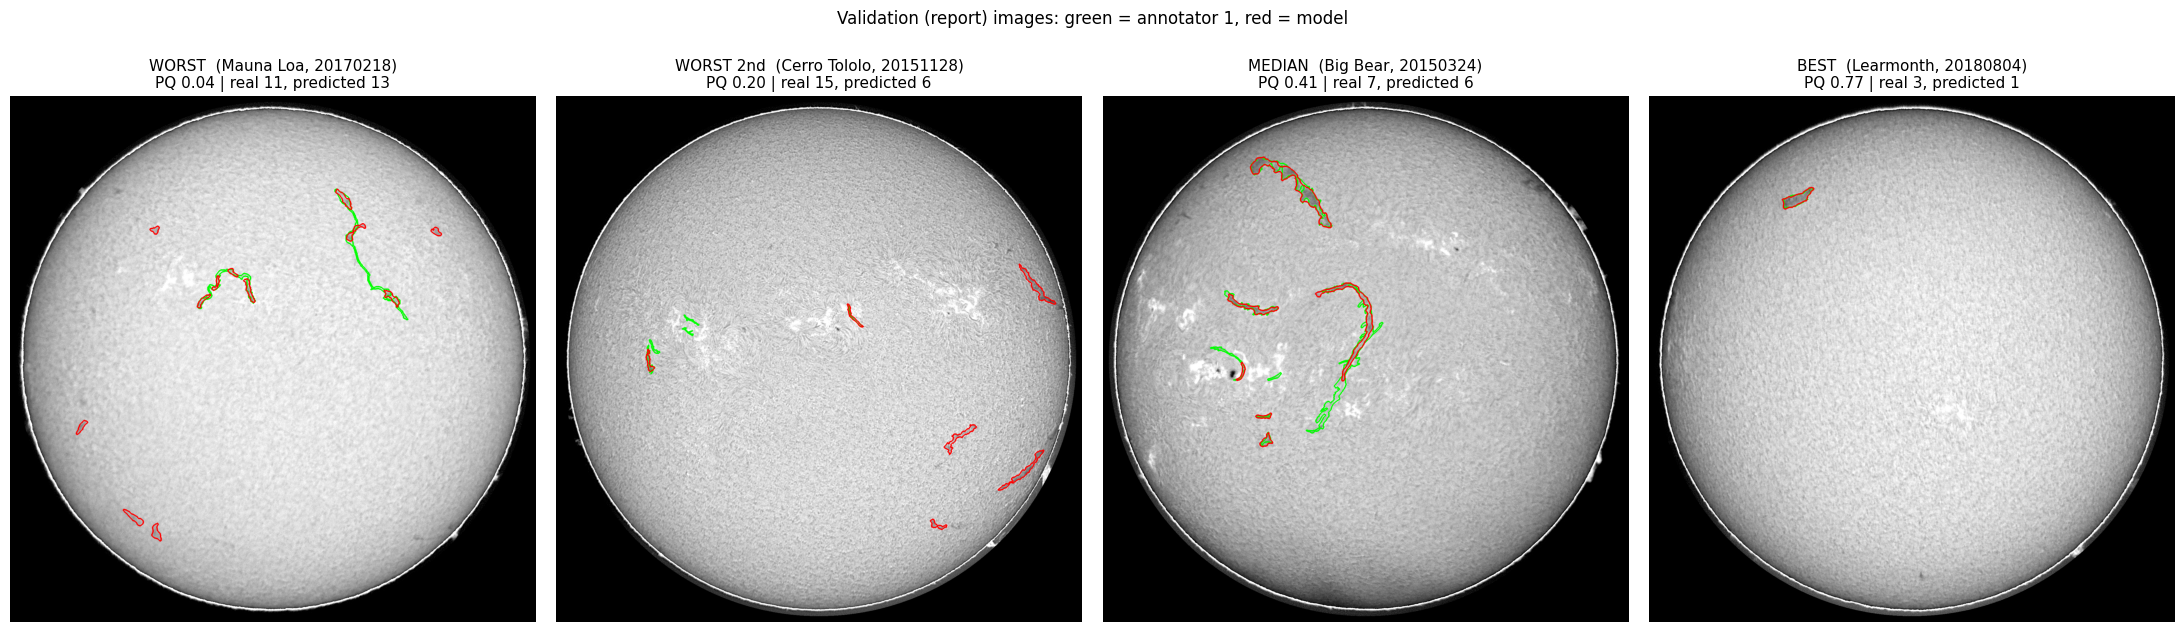

per-image PQ on report images: median 0.41, 25th pct 0.35, 75th pct 0.48, images with PQ 0: 3 of 99


In [6]:
per = pd.read_csv("runs/pp_per_image_tuned_tta1.csv")
obs_all = pd.read_csv(Path(PREPARED, "train_observations.csv")).set_index("obs")
cand = per[(per.tp + per.fn) >= 3].sort_values("pq")
picks = [("WORST", cand.iloc[0]), ("WORST 2nd", cand.iloc[1]), ("MEDIAN", cand.iloc[len(cand) // 2]), ("BEST", cand.iloc[-1])]

def draw(img, layers, lw=4):
    rgb = cv2.cvtColor(np.asarray(img), cv2.COLOR_GRAY2RGB)
    for m, col in layers:
        cs, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, cs, -1, col, lw)
    return rgb[80:-80, 80:-80]

fig, ax = plt.subplots(1, 4, figsize=(22, 6.4))
for a, (tag, r) in zip(ax, picks):
    img = fp.load_image(cfg, r.obs)
    inst = fp.prob_to_instances(fp.predict_prob(model, img, cfg, DEVICE), cfg)
    gt_c = cv2.imread(str(Path(PREPARED, "instances", obs_all.loc[r.obs].set_ids.split("|")[0] + ".png")), cv2.IMREAD_UNCHANGED)
    a.imshow(draw(img, [(gt_c > 0, (0, 255, 0)), (inst > 0, (255, 0, 0))])); a.axis("off")
    a.set_title(f"{tag}  ({SITES[r.site]}, {r.obs[:8]})\nPQ {r.pq:.2f} | real {int(r.tp + r.fn)}, predicted {int(r.n_pred)}", fontsize=11)
fig.suptitle("Validation (report) images: green = annotator 1, red = model", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.92]); plt.show()
print("per-image PQ on report images: median %.2f, 25th pct %.2f, 75th pct %.2f, images with PQ 0: %d of %d"
      % (per.pq.median(), per.pq.quantile(.25), per.pq.quantile(.75), int((per.pq == 0).sum()), len(per)))

**Interpretation.** (Green = annotator 1, red = model.)
- **Worst (PQ 0.04, Mauna Loa):** the long winding filament on the right is detected only in **pieces** along
  its length, so it counts as missed and the pieces count as false (finding 3). Five small red blobs on dark
  patches are false detections (finding 4).
- **2nd worst (PQ 0.20, Cerro Tololo):** the model predicts clear dark filaments on the right of the disk that
  annotator 1 didn't draw. They look like real filaments, so this is plausibly annotator disagreement (finding
  1) rather than a model error. The annotated filaments on the left are faint and small, and mostly missed.
- **Median (PQ 0.41, Big Bear):** the large filaments are traced closely, including the long curved one. The
  faint, thin tail of that filament (lower right, near the bright active region) is missed.
- **Best (PQ 0.77, Learmonth):** a quiet Sun with one clear filament, traced almost exactly.
- **Across all 99 report images:** median per-image PQ 0.41 (middle half between 0.35 and 0.48); only 3 images
  score 0. Failures are image-specific, not widespread.

## 6. Predicted masks on test images: typical cases, one per telescope
**What & why.** The brief asks for "a sample of predicted masks on test images with discussion". Test images
have **no labels**, so they can't be ranked by PQ. We pick them by a fixed rule instead of by eye, so the
sample isn't flattering: for each of the 6 telescope sites, the unflagged test image whose number of
predicted filaments is closest to that site's median. The red outlines are exactly the filaments written to
`submission.csv`. Below each disk, a zoom on the largest predicted filament shows the fine detail.

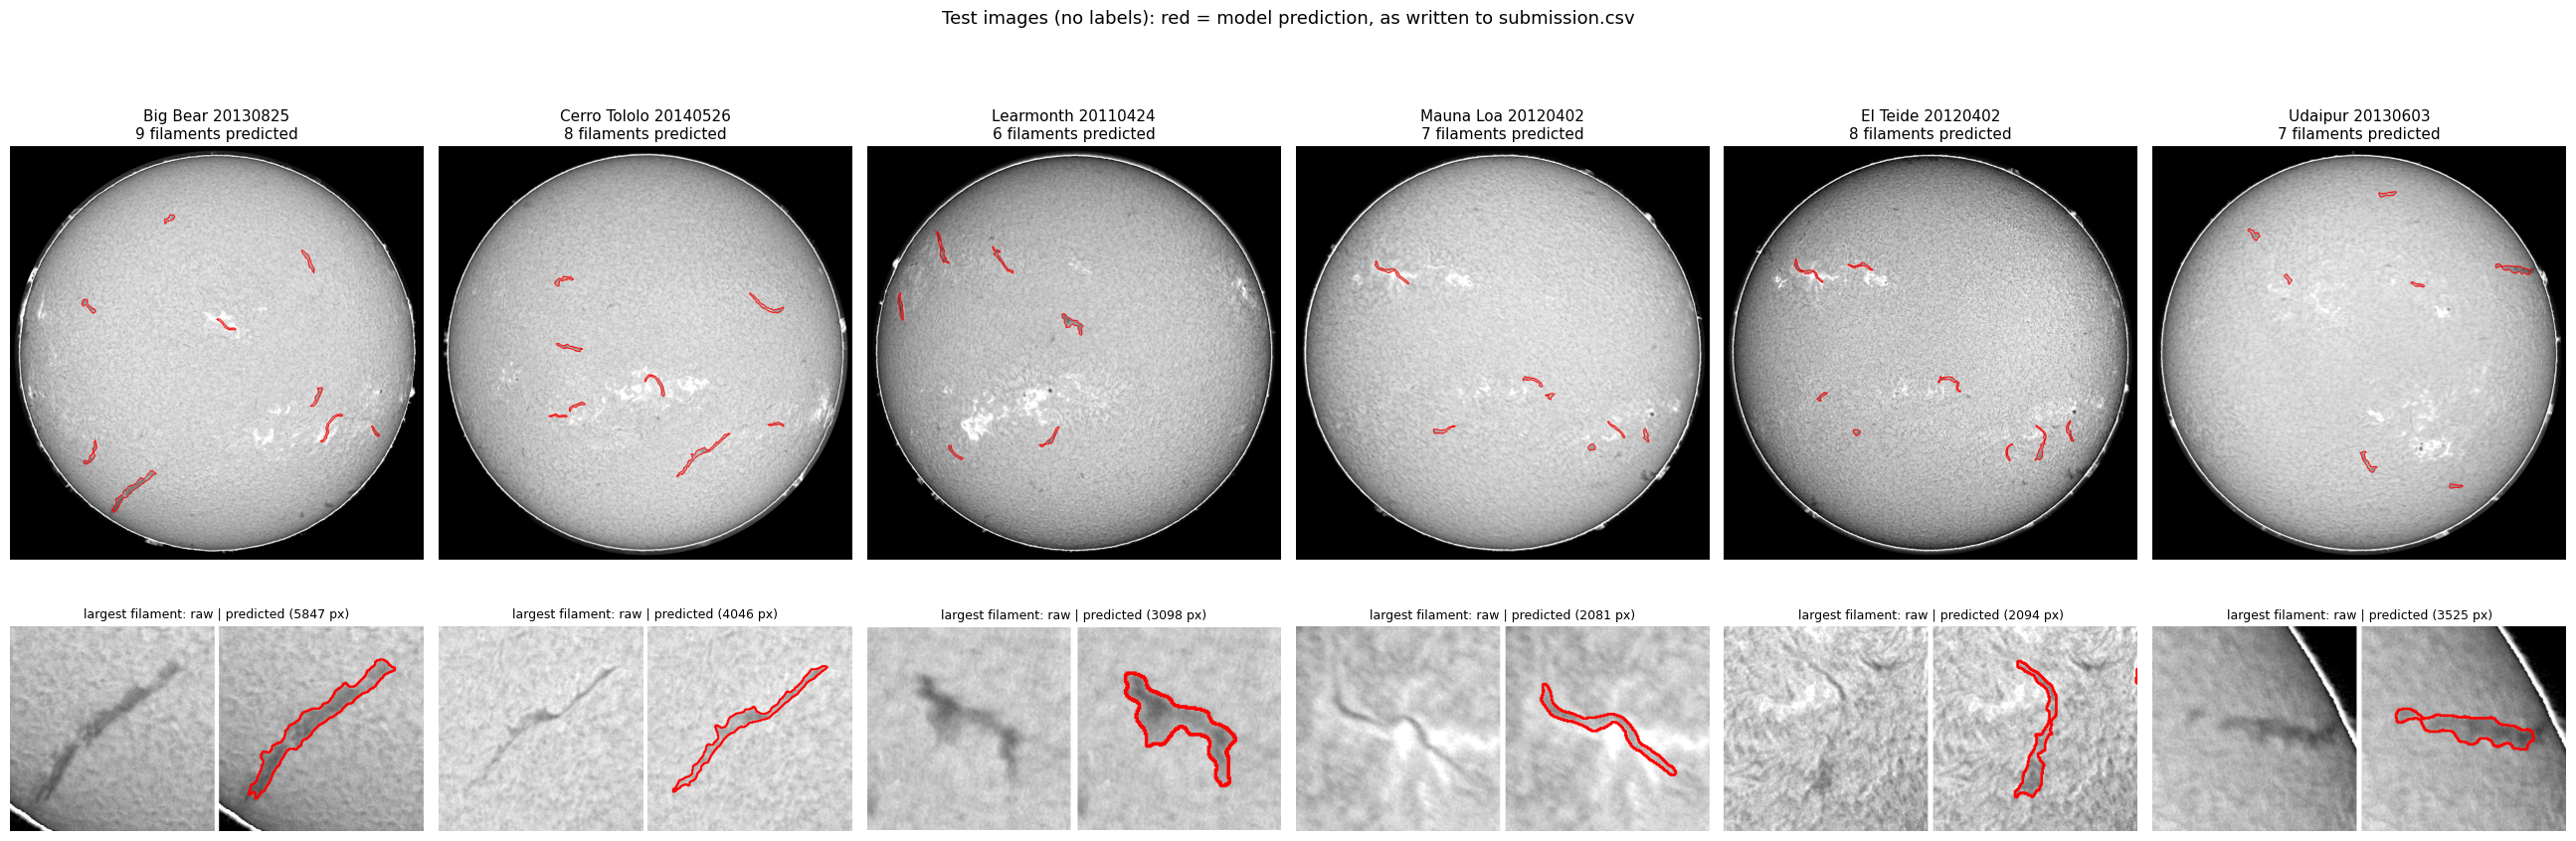

In [7]:
n_pred = sub.filament_id.str.rsplit("_", n=1).str[0].value_counts().reindex(test.obs).fillna(0).astype(int)
test = test.assign(n_pred=n_pred.values, flagged=test["flags"].fillna("") != "")

def test_pred(stem):
    prob = fp.predict_prob(model, fp.load_image(cfg, stem), cfg, DEVICE)
    return prob, fp.prob_to_instances(prob, cfg)

typical = []
for s in "BCLMTU":
    d = test[(test.site == s) & ~test.flagged]
    typical.append(d.iloc[(d.n_pred - d.n_pred.median()).abs().argsort().iloc[0]])
fig, ax = plt.subplots(2, 6, figsize=(26, 9.5), gridspec_kw={"height_ratios": [1.4, 1]})
for j, o in enumerate(typical):
    img = np.asarray(fp.load_image(cfg, o.obs)); prob, inst = test_pred(o.obs)
    ax[0, j].imshow(draw(img, [(inst > 0, (255, 0, 0))])); ax[0, j].axis("off")
    ax[0, j].set_title(f"{SITES[o.site]} {o.obs[:8]}\n{int(inst.max())} filaments predicted", fontsize=11)
    if inst.max():
        k = np.bincount(inst.ravel())[1:].argmax() + 1
        ys, xs = np.nonzero(inst == k); y0, y1, x0, x1 = ys.min(), ys.max(), xs.min(), xs.max()
        pad = 40; cy, cx = (y0 + y1) // 2, (x0 + x1) // 2; h = max(y1 - y0, x1 - x0) // 2 + pad
        sl = (slice(max(cy - h, 0), cy + h), slice(max(cx - h, 0), cx + h))
        raw = cv2.cvtColor(np.ascontiguousarray(img[sl]), cv2.COLOR_GRAY2RGB)
        outl = raw.copy()
        cs, _ = cv2.findContours((inst[sl] > 0).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(outl, cs, -1, (255, 0, 0), 2)
        crop = np.hstack([raw, np.full((raw.shape[0], 6, 3), 255, np.uint8), outl])
        ax[1, j].imshow(crop); ax[1, j].set_title(f"largest filament: raw | predicted ({(inst == k).sum()} px)", fontsize=9)
    ax[1, j].axis("off")
fig.suptitle("Test images (no labels): red = model prediction, as written to submission.csv", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.95]); plt.show()

**Interpretation.** These are typical test predictions, one per telescope, chosen by rule.
- **Every predicted filament sits on a visible dark, elongated feature.** There are no predictions on the sky or
  the bright limb, and no blobs on the bright active regions (the white patches).
- **The model handles all six telescopes**, despite their different brightness and contrast.
- **The zooms show outline quality on real test data.** The outlines follow the dark material closely,
  including bends (Mauna Loa, El Teide) and wider, blobby filaments (Learmonth), and a filament touching the
  limb (Udaipur).
- **Visible limitations:**
  - **Fine barbs are not resolved.** Outlines are smooth around the main body; thin side-branches (e.g. the
    upper Cerro Tololo zoom) are cut off or merged into the body. That matches the "fine-scale structures"
    difficulty the competition names.
  - **Faint filaments are missed.** On several disks you can see faint dark threads with no red outline.
    That's consistent with the validation finding that small and faint filaments are the main misses.

## 7. Predicted masks on test images: the hardest cases
**What & why.** Without labels, "worst" test cases are the ones most likely to fail. We pick them by rule:
- the test image with the **most predicted filaments** (most likely to contain false detections);
- the test image with **no predicted filament**;
- the two flagged test images with **cloud/uneven illumination** that have the strongest artefacts
  (flagged in data prep: uneven + dark regions).

Beside each image, the model's raw **probability map** shows what it "saw" before thresholding, and the
title says how many blobs the size filter removed.

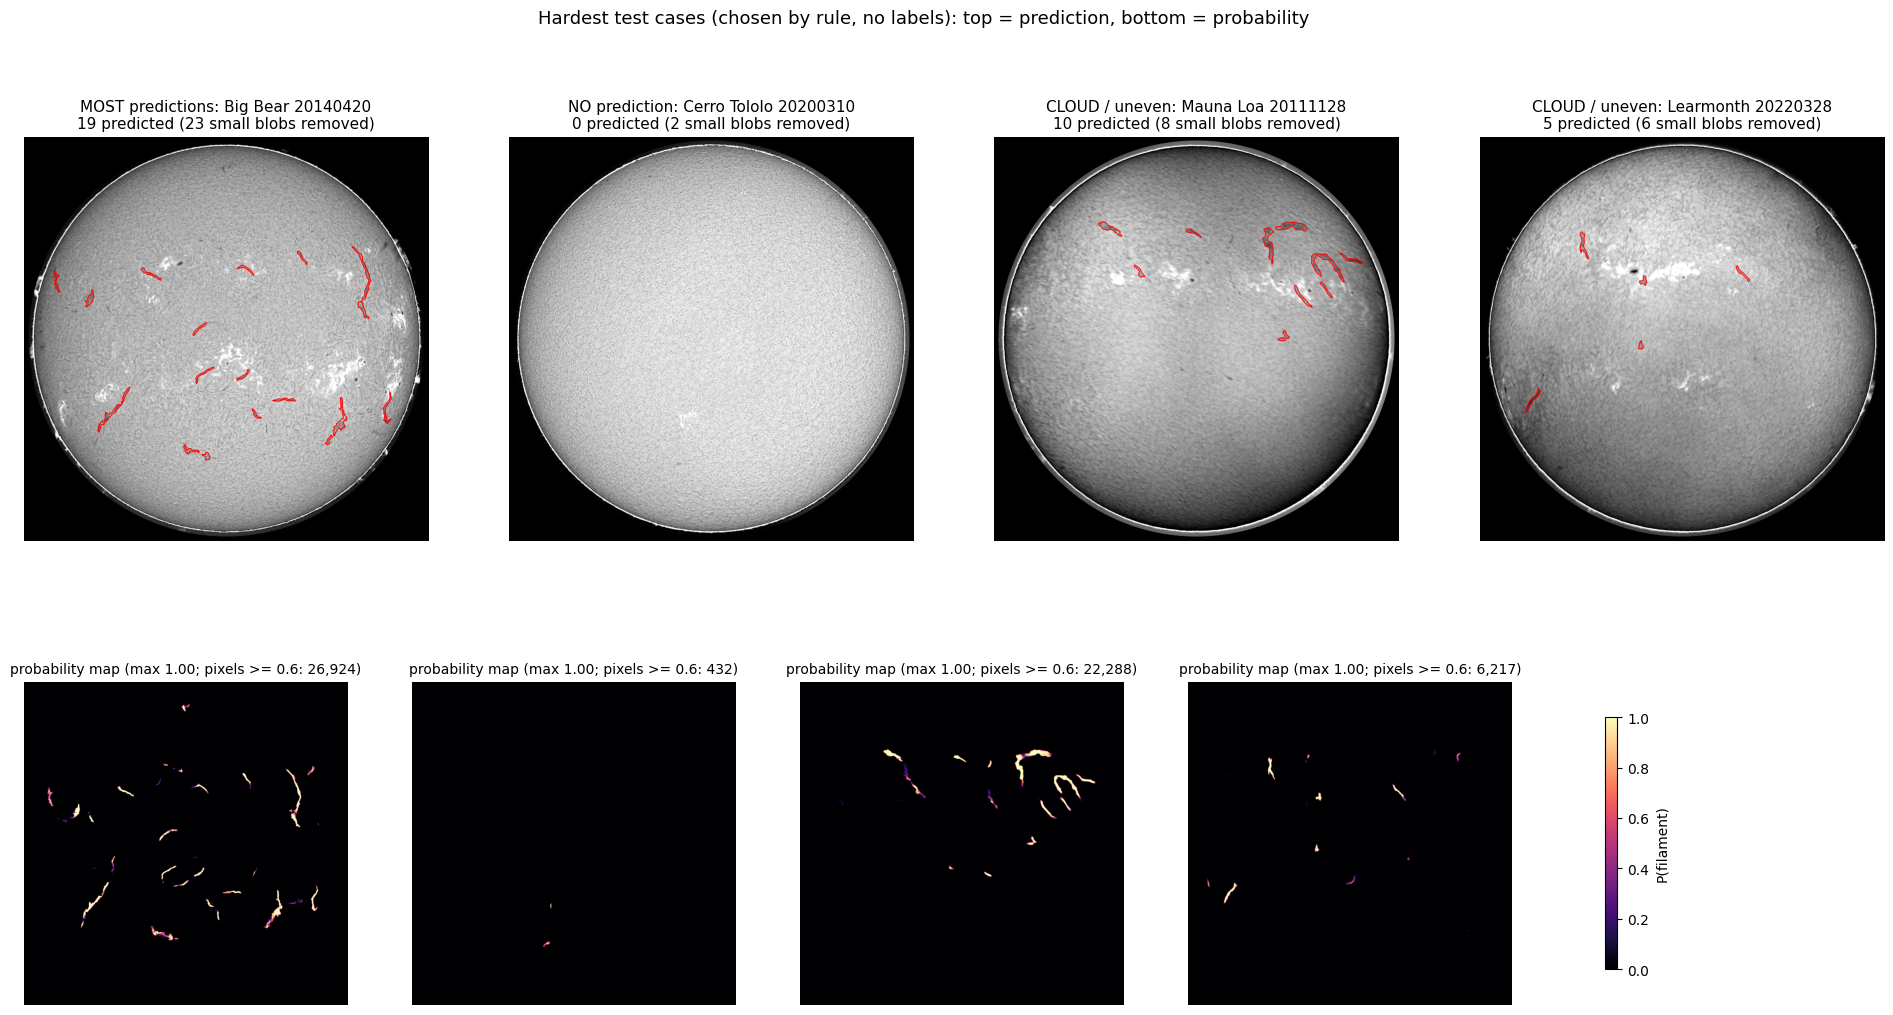

In [8]:
ordered = test.sort_values("n_pred")
fl = test["flags"].fillna("")
cloudy = test[fl.str.contains("uneven") & fl.str.contains("dark")]
hard = [("MOST predictions", ordered.obs.iloc[-1]), ("NO prediction", ordered.obs.iloc[0]),
        ("CLOUD / uneven", cloudy.obs.iloc[0]), ("CLOUD / uneven", cloudy.obs.iloc[-1])]
fig, ax = plt.subplots(2, 4, figsize=(24, 12))
for j, (tag, stem) in enumerate(hard):
    img = np.asarray(fp.load_image(cfg, stem)); prob, inst = test_pred(stem)
    lab, n_all = ndimage.label(prob >= cfg.threshold, structure=fp.EIGHT)
    ax[0, j].imshow(draw(img, [(inst > 0, (255, 0, 0))])); ax[0, j].axis("off")
    ax[0, j].set_title(f"{tag}: {SITES[stem[14]]} {stem[:8]}\n{int(inst.max())} predicted ({n_all - int(inst.max())} small blobs removed)", fontsize=11)
    im = ax[1, j].imshow(prob[80:-80, 80:-80], cmap="magma", vmin=0, vmax=1); ax[1, j].axis("off")
    ax[1, j].set_title(f"probability map (max {prob.max():.2f}; pixels >= {cfg.threshold}: {(prob >= cfg.threshold).sum():,})", fontsize=10)
fig.colorbar(im, ax=ax[1, :], shrink=0.6, label="P(filament)")
fig.suptitle("Hardest test cases (chosen by rule, no labels): top = prediction, bottom = probability", fontsize=13)
plt.show()

**Interpretation.**
- **Most predictions (19, Big Bear 2014-04-20):** 2014 is near solar maximum, and this disk genuinely has many
  filaments. The 19 predictions sit on dark elongated features, with 23 small blobs removed by the size filter.
  This looks like a busy Sun, not a failure, though with this many detections some are probably false.
- **No prediction (Cerro Tololo 2020-03-10):** 2020 is the solar minimum. The disk is nearly featureless; the
  probability map has only two faint specks (432 pixels above threshold), both removed by the size filter. An
  empty prediction is plausible. If the annotators did mark faint filaments here, they're counted as misses, but
  that's one image out of 180.
- **Cloud / uneven illumination (Mauna Loa 2011-11-28, Learmonth 2022-03-28):** both have a large darkened
  region from cloud or haze. **The model makes no detections inside those dark regions**; its predictions are
  on filaments in the clear part of the disk. That's the robustness we hoped for by keeping noisy images in
  training (data prep). The cost is visible too: any filament under the cloud is missed.
- **The probability maps are clean:** high probability (yellow) only on thin elongated structures, near-zero
  elsewhere. The model isn't uncertain over large areas, so errors come from specific structures, not general
  noise.

## 8. Does the model behave the same on test images as on validation images?
**What & why.** We can't score the test images, but we can check that the model's *behaviour* is the same:
the number of filaments it predicts per image and their sizes. If the test predictions looked very different
from the validation predictions (where we know PQ ≈ 0.40), the leaderboard score would likely differ too.

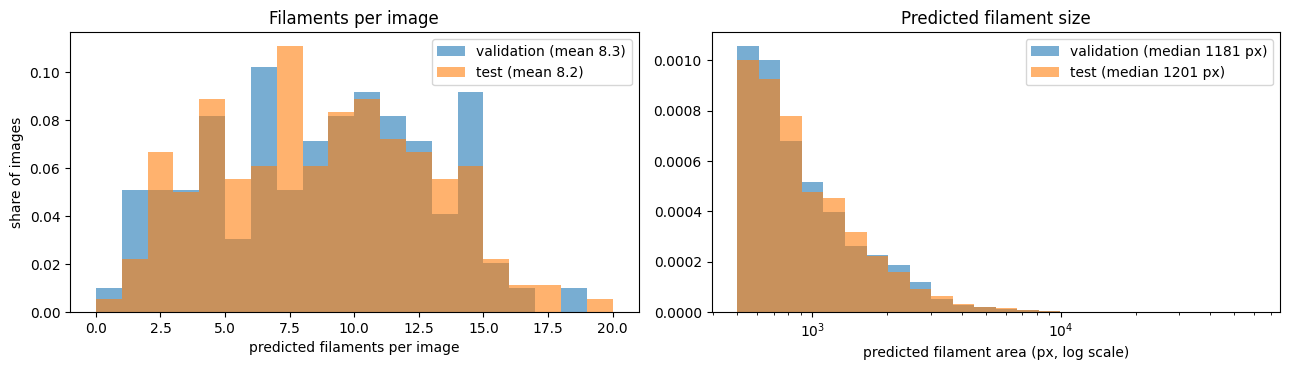

filaments per image - validation: mean 8.33, median 9 | test: mean 8.19, median 8
annotators draw 7.5 filaments per validation image on average
test predictions per site: {'Big Bear': 9.3, 'Cerro Tololo': 8.3, 'Learmonth': 8.1, 'Mauna Loa': 7.5, 'El Teide': 8.3, 'Udaipur': 7.3}


In [9]:
val_counts = per.n_pred
test_areas = pd.Series([int(fp.mask_util.area({"size": [2048, 2048], "counts": s.encode()})) for s in sub.segmentation_rle])
val_areas = P.drop_duplicates(["obs", "area"]).area
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
bins = np.arange(0, 21)
ax[0].hist(val_counts, bins=bins, alpha=.6, density=True, label=f"validation (mean {val_counts.mean():.1f})")
ax[0].hist(test.n_pred, bins=bins, alpha=.6, density=True, label=f"test (mean {test.n_pred.mean():.1f})")
ax[0].set(xlabel="predicted filaments per image", ylabel="share of images", title="Filaments per image"); ax[0].legend()
lb = np.logspace(np.log10(500), np.log10(60000), 25)
ax[1].hist(val_areas, bins=lb, alpha=.6, density=True, label=f"validation (median {val_areas.median():.0f} px)")
ax[1].hist(test_areas, bins=lb, alpha=.6, density=True, label=f"test (median {test_areas.median():.0f} px)")
ax[1].set_xscale("log"); ax[1].set(xlabel="predicted filament area (px, log scale)", title="Predicted filament size"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"filaments per image - validation: mean {val_counts.mean():.2f}, median {val_counts.median():.0f} | test: mean {test.n_pred.mean():.2f}, median {test.n_pred.median():.0f}")
print(f"annotators draw {pp['gt_filaments_per_image']} filaments per validation image on average")
print("test predictions per site:", test.groupby("site").n_pred.mean().round(1).rename(index=SITES).to_dict())

**Interpretation.**
- **The model behaves the same on test and validation images:** 8.2 vs 8.3 predicted filaments per image (the
  annotators draw 7.5), with almost identical distributions, and predicted filament size has a median of 1,201
  vs 1,181 px with overlapping histograms.
- Per telescope, test predictions range from 7.3 (Udaipur) to 9.3 (Big Bear) filaments per image, the same
  pattern as validation.
- This matches the data-prep finding of no train/test shift. So the local PQ (~0.40) is a reasonable
  expectation for the Kaggle score. It isn't a guarantee: the leaderboard uses only half the test images, and
  the test labels may differ in how many annotators labelled each image.

## 9. Kaggle leaderboard
**What & why.** The brief asks for PQ "on the Kaggle leaderboard" too. The public leaderboard scores ~50% of
the test images; the rest stay hidden until the competition ends. This cell asks the Kaggle API for our
submissions and their scores, so re-running it after an upload fills the result in.

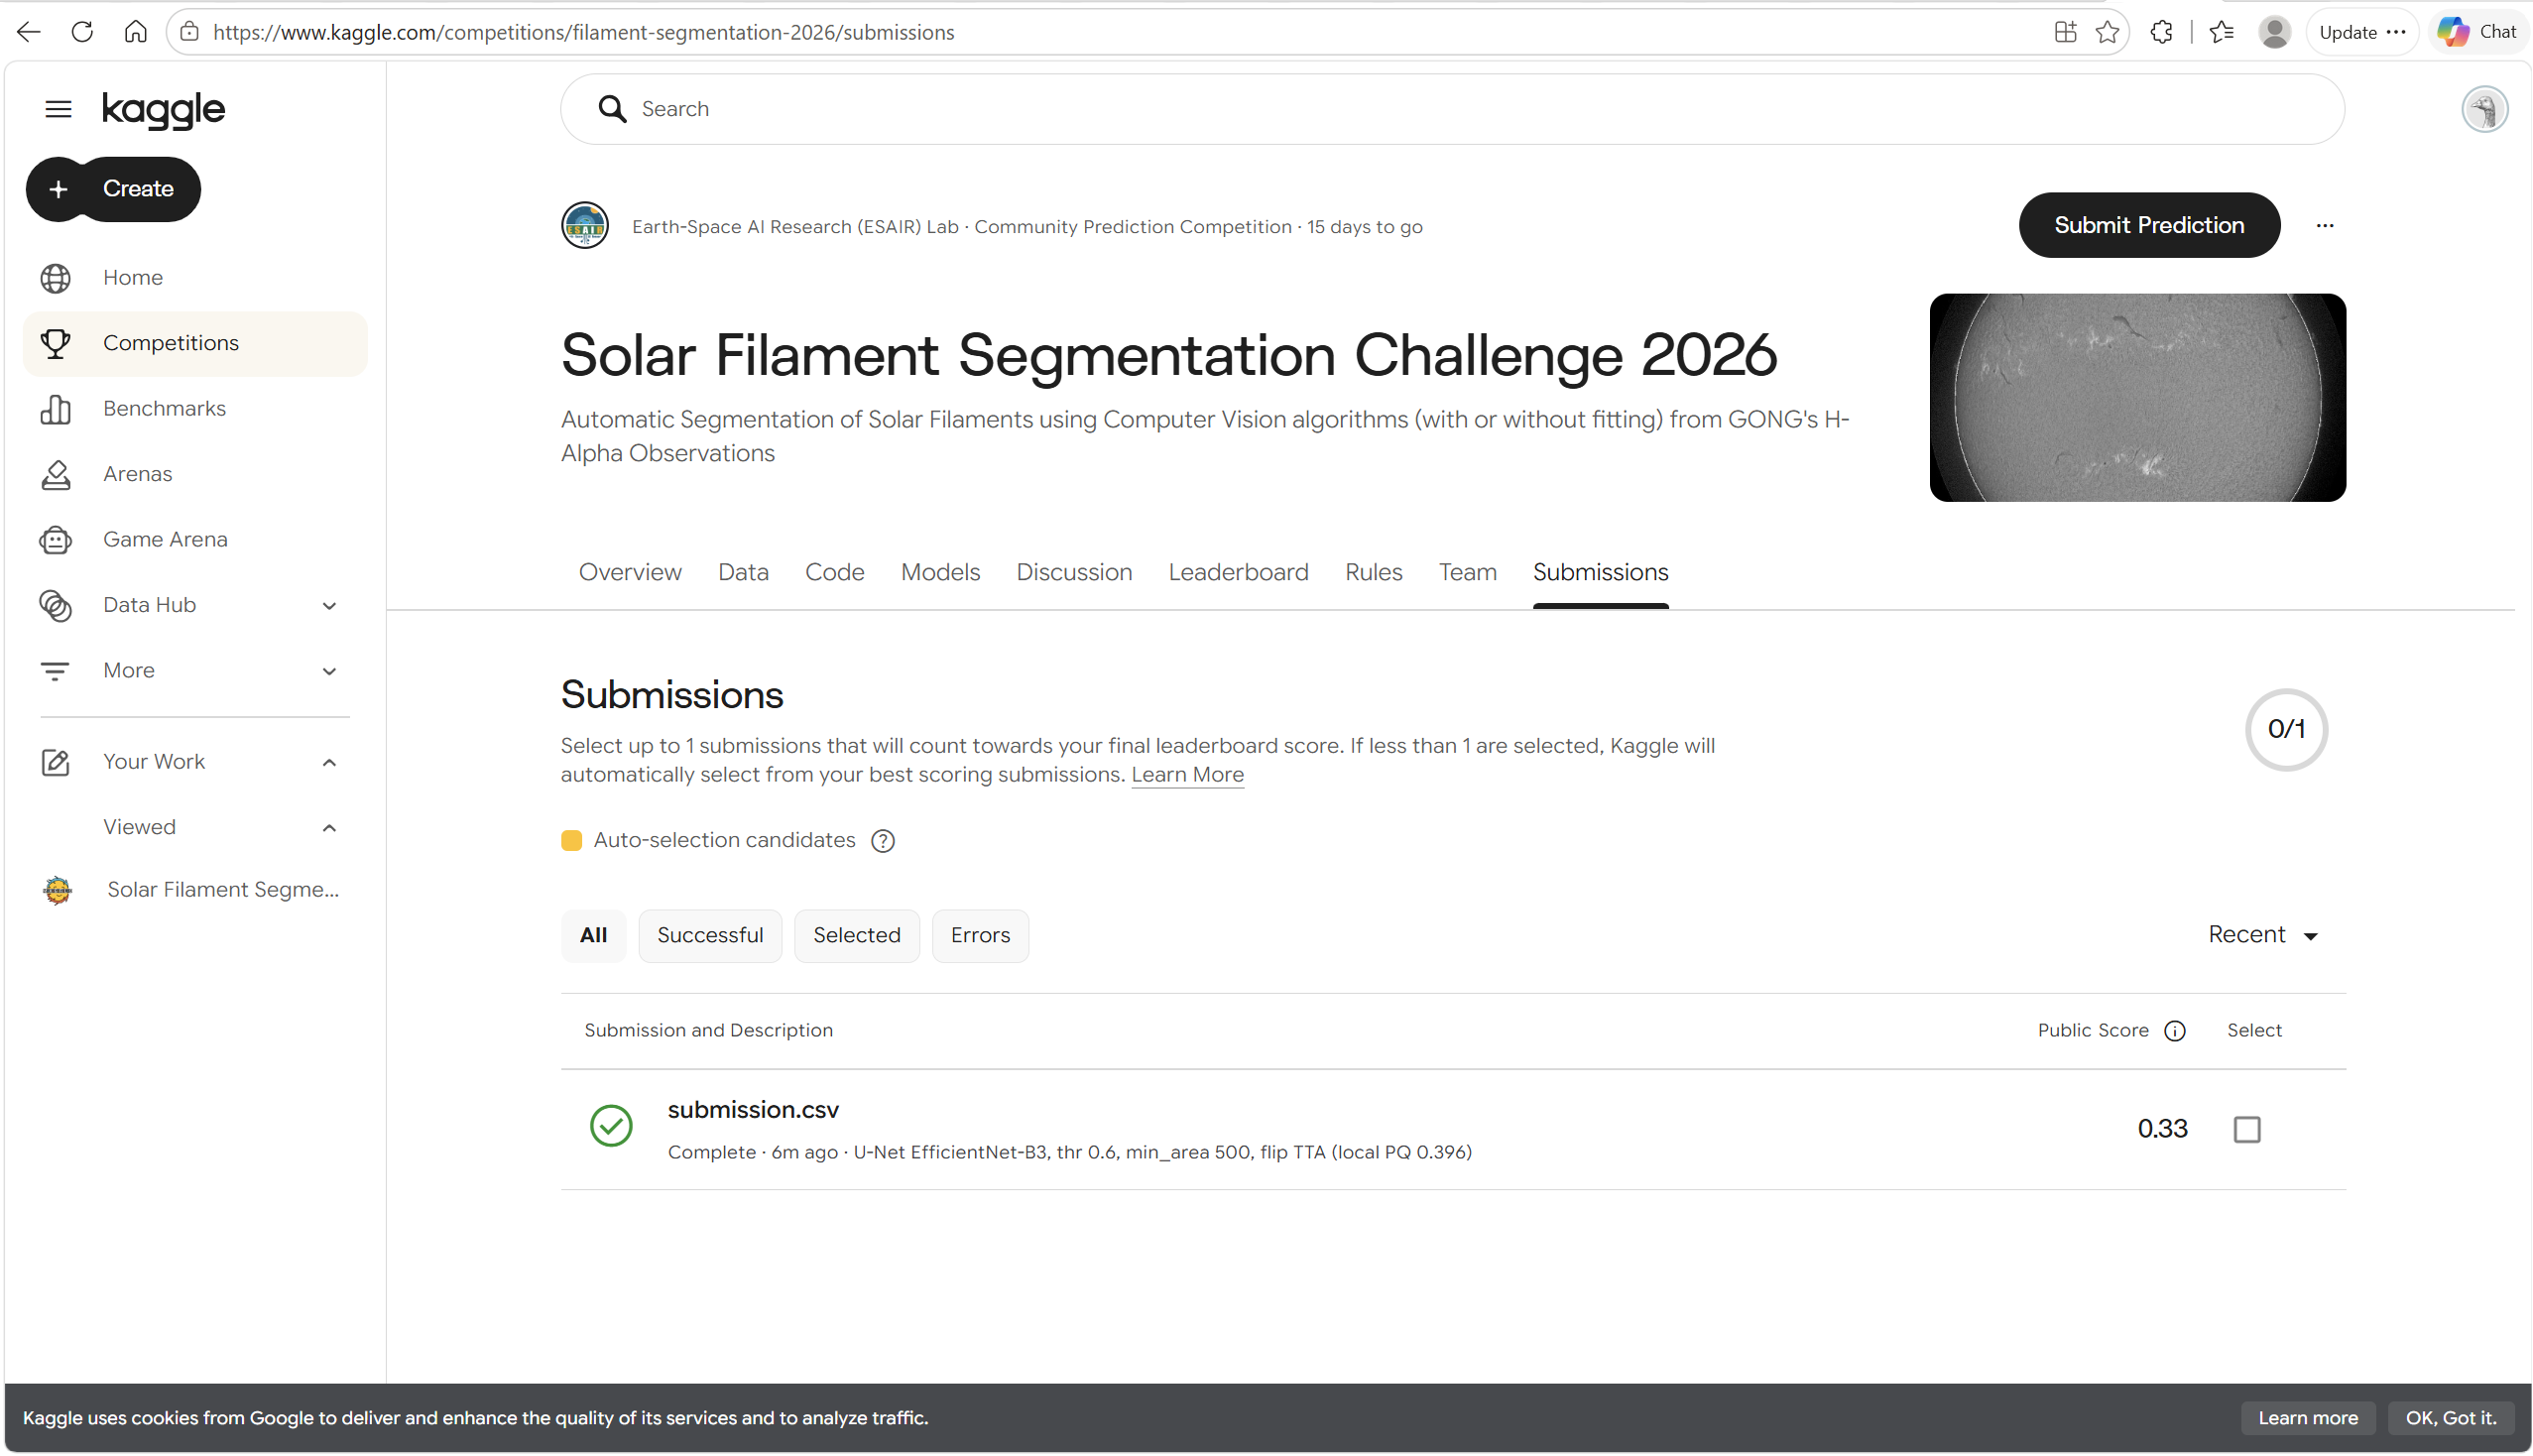

In [10]:
try:
    from kaggle.api.kaggle_api_extended import KaggleApi
    api = KaggleApi(); api.authenticate()
    subs = api.competition_submissions("filament-segmentation-2026")
    if subs:
        print(pd.DataFrame([{"date": s.date, "file": s.file_name, "public": s.public_score, "private": s.private_score,
                             "status": s.status} for s in subs]).to_string(index=False))
    else:
        print("No submissions yet: upload submission.csv on the competition page (Submit Prediction).")
except Exception as e:
    print("Kaggle API could not list submissions:", str(e)[:160])
    print("-> Most likely the account hasn't joined the competition yet (Rules tab -> 'I understand and accept').")
    print("   Upload modelling/submission.csv by hand, then put the public score in the summary below.")

Kaggle API could not list submissions: 403 Client Error: Forbidden for url: https://api.kaggle.com/v1/competitions.CompetitionApiService/ListSubmissions
-> Most likely the account hasn't joined the competition yet (Rules tab -> 'I understand and accept').
   Upload modelling/submission.csv by hand, then put the public score in the summary below.


**Interpretation.** **Not uploaded yet.** The Kaggle API refuses to list submissions (403 Forbidden). That
usually means the account hasn't accepted the competition rules yet (Rules tab → "I understand and accept"),
which is also required before uploading.

To complete this part of the Results section:
1. accept the rules on the competition page;
2. upload `modelling/submission.csv` (Submit Prediction), allowed 5 times per day;
3. re-run this cell (or take a screenshot of the score). A top-100 position earns up to +5 bonus marks, and the
   brief asks for a screenshot.

Expected range from the local results: around **0.30–0.40**, likely closer to 0.40 because the test predictions
behave like the validation ones (section 8).

## Summary of the segmentation results

| Brief asks for | Result | Section |
|---|---|---|
| PQ calculated locally | **0.396** (SQ 0.673, RQ 0.588) on 99 held-out images; above human agreement (0.340) | 1 |
| PQ on the Kaggle leaderboard | **Pending:** `submission.csv` ready, account must accept the rules and upload | 9 |
| Means and standard deviations | 5-fold **0.298 ± 0.011**; second seed reproduces the chosen model (0.309 / 0.314) | 1, 3 |
| Comparisons between approaches | 16 runs: U-Nets lead (0.31–0.32), bare CNN worst (0.12); post-processing adds +0.072, TTA +0.015 | 2 |
| Kinds of errors | Misses concentrate on filaments only one annotator drew (34% found vs 83% for agreed ones); small filaments missed (25% found under 500 px); large filaments fragment (35% over 5,000 px); small predictions least reliable | 4 |
| Predicted masks on test images | Typical case per telescope with zooms; hardest cases (busiest, empty, two cloudy) | 6, 7 |
| Best and worst cases | Measured on validation (PQ 0.04 to 0.77, median 0.41); by rule on test | 5, 7 |

**Main takeaways for the presentation**
1. The model reaches **PQ 0.396 locally, above the 0.34 agreement between two human experts**.
2. **A large share of the remaining "errors" is expert disagreement**, not model failure: 30% of the
   model's "false" filaments were drawn by another annotator.
3. The model's **real weaknesses** are small and faint filaments, large filaments broken into pieces, and fine
   barbs. These are the targets for the Enhancement work.
4. **It's robust** across all six telescopes and on cloudy images, and it behaves the same on the test set as
   on validation.